# Эксперименты с нейросетями: анализ тональности текста

Вы работаете в команде картографического сервиса YouMap, который собирает отзывы о компаниях, организациях, квартирах и других заведениях из разных источников. Команде качества нужно научиться автоматически находить негативные сообщения и передавать их на приоритетную обработку. Ваша задача — подготовить данные, обучить модель и объяснить, какой подход лучше помогает находить негативные отзывы.

Вам предстоит использовать датасет `ds_s26_geo_reviews.csv`.

|Признак|Описание|Комментарий|
|:---|:---|:---|
|text|Текст отзыва|Отзывы для обучения нейросети|
|address|Адрес организации|Только для EDA|
|federal_district|Федеральный округ|Категориальный признак|
|name_ru|Название организации|Только для EDA. <br> Не используйте его для обучения|
|rubrics|Категории, к которым относится организация|Только для EDA|
|rubrics_count|Количество категорий, к которым относится организация|Числовой признак|
|review_len_chars|Длина отзыва в символах|Числовой признак|
|review_len_words|Длина отзыва в словах|Числовой признак|
|emoji_count|Количество эмодзи в отзыве|Числовой признак|
|target|1 — негативный отзыв, оценка 1–2. <br> 0 — остальные отзывы, оценка 3–5.|Целевая переменная|

В проекте вы сравните два способа представить один и тот же текст для нейросети:

*   Числовые признаки текста + MLP.
*   Индексы токенов + эмбеддинги + mean pool +  MLP.

Основная метрика — PR-AUC, вспомогательные — ROC-AUC, precision, recall, F1-мера.

## Шаг 1. Импорт библиотек, настройка констант, обеспечение воспроизводимости

In [3]:
from pathlib import Path
from collections import Counter
import random
import re
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

from IPython.display import display

In [4]:
RANDOM_STATE = 42
DATA_PATH = Path("/datasets/ds_s26_geo_reviews")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)


def set_seed(seed: int = RANDOM_STATE) -> None:
    # Зафиксируйте random seed для random, numpy и torch
    random.seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)
    torch.cuda.manual_seed_all(RANDOM_STATE)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(RANDOM_STATE)

# Определите устройство: cuda по доступности, иначе cpu
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
device

device(type='cpu')

## Шаг 2. Загрузка данных и исследовательский анализ

EDA в этом проекте — короткий блок для знакомства с данными, в котором весь код уже написан. Он поможет понять размер датасета, проанализировать целевую переменную, проверить дисбаланс классов и пропуски.

Запустите ячейки, посмотрите на результаты и переходите к оформлению выводов.

In [6]:
# Код для EDA готов: запустите ячейки и изучите выводы
df = pd.read_csv(DATA_PATH)

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Размер датасета: 11796 строк, 10 столбцов


,text,address,federal_district,name_ru,rubrics,rubrics_count,review_len_chars,review_len_words,emoji_count,target
0,Бронировала квартиру в Тюмени. Бронирование пр...,"Челябинск, проспект Ленина, 21В",Уральский ФО,Квартирка,Информационный интернет-сайт;Агентство недвижи...,2,121,14,0,0
1,Праздновали Новый год в этом отеле.\nСамое пот...,"Иркутский район, Листвянское муниципальное обр...",Сибирский ФО,Байкал Хан,Гостиница,1,577,89,0,0
2,"Очень нравится грумер Анна, всегда приветливая...","Московская область, Королёв, Подмосковная улиц...",Центральный ФО,Счастливые хвостатые,"Зоосалон, зоопарикмахерская;Зоомагазин",3,434,67,0,0
3,В городе Салават директора на месте невозможно...,"Республика Башкортостан, Салават, улица Ленина...",Приволжский ФО,Спортмастер,Спортивный магазин;Спортивная одежда и обувь;Т...,3,201,32,0,1
4,Огромное спасибо за заказ.\nЗаказ очень хорошо...,"Москва, Троицкая улица, 7/1с1",Центральный ФО,Дом Чая,Магазин чая;Магазин посуды,2,183,27,0,0


In [7]:
# Типы данных, пропуски и количество уникальных значений
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
}))

,dtype,missing,unique
text,str,0,11796
address,str,0,10614
federal_district,str,0,8
name_ru,str,25,9012
rubrics,str,0,3287
rubrics_count,int64,0,9
review_len_chars,int64,0,1193
review_len_words,int64,0,302
emoji_count,int64,0,22
target,int64,0,2


,target,count,share
0,0,10723,0.909037
1,1,1073,0.090963


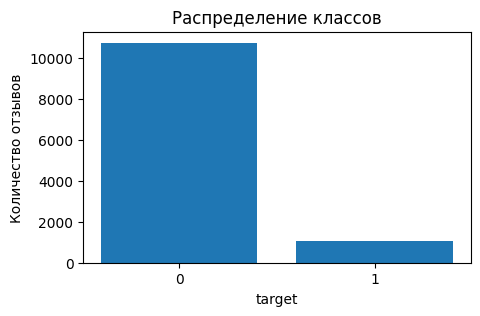

In [8]:
# Распределение классов: количество объектов каждого класса и их доля
target_distribution = (
    df["target"]
    .value_counts()
    .sort_index()
    .rename_axis("target")
    .reset_index(name="count")
)
target_distribution["share"] = target_distribution["count"] / len(df)

display(target_distribution)

plt.figure(figsize=(5, 3))
plt.bar(target_distribution["target"].astype(str), target_distribution["count"])
plt.title("Распределение классов")
plt.xlabel("target")
plt.ylabel("Количество отзывов")
plt.show()

In [9]:
pd.set_option("display.max_colwidth", 220)

# Примеры объектов каждого класса: посмотрите, как выглядит текстовая разметка
for class_value, title in [(0, "ненегативные отзывы"), (1, "негативные отзывы")]:
    print(f"Примеры: {title}")
    examples = (
        df[df["target"] == class_value]
        [["text", "federal_district", "rubrics_count", "review_len_words", "emoji_count", "target"]]
        .sample(3, random_state=RANDOM_STATE)
    )
    display(examples)

Примеры: ненегативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
1809,"Спасибо, Дмитрию за грамотный подбор экипировки для детей",Центральный ФО,3,8,0,0
3561,"Мне очень понравилось! Зашла туда случайно, хотелось выпить кофе с чем-нибудь вкусненьким.. Официантка очень приветливая и обходительная, предложила выбрать место, в зале очень уютно. Попробовала тосты с авокадо и Бо...",Центральный ФО,1,43,0,0
10301,"Всё просто супер! В номере есть всё необходимое, для автономного проживания. Особенно радует небольшая кухня с посудой, столовыми приборами, микроволновкой, электрочайником и плитой. А прямо под окнами есть супермарк...",Сибирский ФО,1,116,0,0


Примеры: негативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
10728,"Совершенно отвратительное поведение дирекции: нужно было проехать по дороге (городская территория, как и весь МУП Рынок) - разгрузиться у соседнего здания. Как оказалось, въезд/проезд/пролёт на ранок стоит 800 рублей...",Центральный ФО,1,52,0,1
8118,"Купил велик ребёнку, он сломался через 3 недели эксплуатации, приехали в сервис, но тут его не приняли, записать могут через неделю не раньше, на просьбу уделить 2 минуты и оценить масштаб ремонта тоже отказали, хо...",Центральный ФО,2,88,0,1
11716,Ни в коем случае не посещайте данную мойку!\nПродолжают списывать деньги с карты после единоразового посещения!!!\nСписывают без моего ведома!,Центральный ФО,2,20,0,1


Сформулируйте выводы, кратко ответив на вопросы:

* Насколько классы сбалансированы?

* Почему accuracy здесь может вводить в заблуждение?

* Какие пропуски обнаружились и как с ними нужно поступить?

* Почему важно помнить, что `target` получен из пользовательских оценок, а не ручной разметкой текста?

  * В датасете 11 796 отзывов: 1 073 негативных (target = 1, 9,10%) и 10 723 ненегативных (target = 0, 90,90%). Наблюдается дисбаланс классов - на один негативный отзыв приходится примерно десять остальных
  * Из-за дисбаланса классов accuracy будет не лучшей метрикой, например, если модель будет предсказывать 0 для каждой записи, тогда accuracy составит 0,9090, хотя в действительности модель вообще не различает классы
  * Найдено 25 пропусков в `name_ru`, так как этот признак используется только в EDA, поэтому как-либо менять его не требуется
  * Целевая переменная потенциально может быть шумным признаком: оценка пользователя может зависеть не только от содержания или эмоциональной окраски текста, но и от других факторов

## Шаг 3. Подготовка числовых признаков

Для первого эксперимента используйте готовые числовые признаки, закодированный признак `federal_district` и самостоятельно извлечённые из текста числовые показатели:

- `punct_count` — количество знаков препинания.
- `question_count` — количество вопросительных знаков.
- `exclamation_count` — количество восклицательных знаков.
- `newline_count` — количество переносов строк.
- `digit_count` — количество цифр.
- `uppercase_share` — доля заглавных букв среди всех букв.
- `avg_word_len` — средняя длина слова.

Выделив все признаки, разделите данные на обучающую, валидационную и тестовую выборки, а затем подготовьте данные для нейросети, создав объекты классов `Dataset` и `DataLoader`. Это же разделение нужно будет использовать и в эксперименте с текстовой моделью, чтобы сравнение было честным.

Не используйте признаки `name_ru`, `address` и `rubrics` в модели: они нужны для знакомства с данными, но могут привести к запоминанию конкретных организаций или слишком детальных категорий.

In [13]:
df_features = df.copy()

# В датафрейме переносы строк записаны как \n
df_features["text"] = (
    df_features["text"].astype(str)
    .str.replace("\\r\\n", "\n", regex=False)
    .str.replace("\\n", "\n", regex=False)
)

text = df_features["text"].astype(str)

punctuation = string.punctuation + "«»—–…“”„"

# 1. Количество знаков препинания
df_features["punct_count"] = text.str.count(
    f"[{re.escape(punctuation)}]"
)

# 2. Количество вопросительных знаков
df_features["question_count"] = text.str.count(r"\?")

# 3. Количество восклицательных знаков
df_features["exclamation_count"] = text.str.count("!")

# 4. Количество переносов строк
df_features["newline_count"] = text.str.count(r"\n")

# 5. Количество цифр
df_features["digit_count"] = text.str.count(r"\d")

# 6. Доля заглавных букв среди всех букв
# Сначала посчитайте общее число букв и число заглавных букв
letters_count = text.str.count(r"[A-Za-zА-Яа-яЁё]")
upper_count = text.str.count(r"[A-ZА-ЯЁ]")
df_features["uppercase_share"] = upper_count / letters_count
df_features["uppercase_share"] = df_features["uppercase_share"].fillna(0)

# 7. Средняя длина слова
df_features["avg_word_len"] = text.apply(
    lambda s: (
        sum(len(word) for word in s.split()) / len(s.split())
        if len(s.split()) > 0
        else 0
    )
)
df_features["avg_word_len"] = df_features["avg_word_len"].fillna(0)

numeric_features = [
    "rubrics_count",
    "review_len_chars",
    "review_len_words",
    "emoji_count",
    "punct_count",
    "question_count",
    "exclamation_count",
    "newline_count",
    "digit_count",
    "uppercase_share",
    "avg_word_len",
]

categorical_features = ["federal_district"]

display(df_features[numeric_features + ["target"]].describe().T)

district_distribution = (
    df_features["federal_district"]
    .value_counts()
    .rename_axis("federal_district")
    .reset_index(name="count")
)
district_distribution["share"] = district_distribution["count"] / len(df_features)
display(district_distribution)

,count,mean,std,min,25%,50%,75%,max
rubrics_count,11796.0,1.982791,1.095271,1.0,1.000000,2.00000,3.000000,10.00
review_len_chars,11796.0,303.248813,290.872870,13.0,145.000000,214.00000,362.000000,5460.00
review_len_words,11796.0,44.412004,45.423441,3.0,20.000000,31.00000,53.000000,923.00
emoji_count,11796.0,0.320787,2.009054,0.0,0.000000,0.00000,0.000000,173.00
punct_count,11796.0,11.315276,11.419662,0.0,5.000000,8.00000,13.000000,180.00
question_count,11796.0,0.054256,0.393383,0.0,0.000000,0.00000,0.000000,10.00
exclamation_count,11796.0,1.123093,2.346631,0.0,0.000000,0.00000,1.000000,35.00
newline_count,11796.0,0.770515,2.177689,0.0,0.000000,0.00000,0.000000,34.00
digit_count,11796.0,1.141573,3.270892,0.0,0.000000,0.00000,1.000000,92.00
uppercase_share,11796.0,0.028036,0.016363,0.0,0.017857,0.02543,0.034722,0.34


,federal_district,count,share
0,Центральный ФО,4922,0.417260
1,Северо-Западный ФО,1922,0.162937
2,Южный ФО,1766,0.149712
3,Приволжский ФО,1547,0.131146
4,Сибирский ФО,589,0.049932
5,Уральский ФО,519,0.043998
6,Северо-Кавказский ФО,364,0.030858
7,Дальневосточный ФО,167,0.014157


In [14]:
# Разделите данные на обучающую, валидационную и тестовую выборки в пропорции 70:15:15
# Не забудьте про стратификацию, чтобы сохранить долю негативных отзывов
train_df, temp_df = train_test_split(
    df_features,
    test_size=0.3,
    stratify=df_features['target'],
    random_state=RANDOM_STATE,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['target'],
    random_state=RANDOM_STATE,
)

split_stats = pd.DataFrame(
    {
        "rows": [len(train_df), len(val_df), len(test_df)],
        "target_share": [
            train_df["target"].mean(),
            val_df["target"].mean(),
            test_df["target"].mean(),
        ],
    },
    index=["обучающая", "валидационная", "тестовая"],
)

display(split_stats)

,rows,target_share
обучающая,8257,0.090953
валидационная,1769,0.091012
тестовая,1770,0.090960


In [15]:
# Создайте scaler для числовых признаков и encoder для federal_district
scaler = StandardScaler()
one_hot_encoder = OneHotEncoder(
    drop='first',
    handle_unknown='ignore',
    sparse_output=False
)


# Важно: fit только на обучающей выборке, для валидационной и тестовой используйте transform
X_train_num = scaler.fit_transform(
    train_df[numeric_features]
)
X_val_num = scaler.transform(
    val_df[numeric_features]
)
X_test_num = scaler.transform(
    test_df[numeric_features]
)

X_train_cat = one_hot_encoder.fit_transform(
    train_df[categorical_features]
)
X_val_cat = one_hot_encoder.transform(
    val_df[categorical_features]
)
X_test_cat = one_hot_encoder.transform(
    test_df[categorical_features]
)

X_train = np.hstack([X_train_num, X_train_cat]).astype("float32")
X_val = np.hstack([X_val_num, X_val_cat]).astype("float32")
X_test = np.hstack([X_test_num, X_test_cat]).astype("float32")

y_train = train_df["target"].values.astype("float32")
y_val = val_df["target"].values.astype("float32")
y_test = test_df["target"].values.astype("float32")

feature_names = numeric_features + list(
    one_hot_encoder.get_feature_names_out(categorical_features)
)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Количество признаков после кодирования:", len(feature_names))
display(pd.DataFrame({"feature": feature_names}))

X_train: (8257, 18) X_val: (1769, 18) X_test: (1770, 18)
Количество признаков после кодирования: 18


,feature
0,rubrics_count
1,review_len_chars
2,review_len_words
3,emoji_count
4,punct_count
5,question_count
6,exclamation_count
7,newline_count
8,digit_count
9,uppercase_share


In [16]:
# Создание Dataset и DataLoader

class ReviewsDataset(Dataset):
    def __init__(self, features: np.ndarray, target: np.ndarray):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32).unsqueeze(1) # Добавил .unsqueeze(1)

    def __len__(self):
        # Верните количество объектов в датасете
        return self.features.shape[0]

    def __getitem__(self, idx):
        # Верните пару: признаки объекта и целевую метку
        return self.features[idx], self.target[idx]


BATCH_SIZE = 128

numeric_loaders = {
    "train": DataLoader(
        ReviewsDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsDataset(X_test, y_test),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

features_batch, target_batch = next(iter(numeric_loaders["train"]))
print("features_batch:", features_batch.shape, features_batch.dtype)
print("target_batch:", target_batch.shape, target_batch.dtype)

features_batch: torch.Size([128, 18]) torch.float32
target_batch: torch.Size([128, 1]) torch.float32


## Шаг 4. Эксперимент 1 — MLP на числовых признаках

Обучите несколько MLP-конфигураций. Во всех экспериментах используйте одно и то же разделение на выборки и одну и ту же функцию потерь.

Дополните код функций:

- `train_epoch` — нужна для одного прохода по обучающей выборке.
- `evaluate` — нужна для оценки на валидационной или тестовой выборках.

Функция `run_experiment` уже готова, её можно переиспользовать.

Из-за дисбаланса классов нужно добавить коэффициент `pos_weight` в `BCEWithLogitsLoss`. Это созданный для работы с нейросетями вариант модификации (взвешивания) функции потерь — знакомого вам метода борьбы с дисбалансом классов. Благодаря `pos_weight` ошибки на редком классе 1 получат больший вес. Это не отменяет необходимости выбирать конфигурации по PR-AUC и дополнительно анализировать ROC-AUC, precision, recall и F1.

In [18]:
def calc_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float = 0.5) -> dict:
    # PR-AUC и ROC-AUC считайте по вероятностям y_prob
    # Для precision, recall, F1 и accuracy сначала переведите вероятности в классы
    # В этом проекте используйте порог по умолчанию: threshold = 0.5
    y_pred = (y_prob >= threshold).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0,
    )

    return {
        "pr_auc": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy_score(y_true, y_pred),
    }


majority_accuracy = (test_df["target"] == 0).mean()
print(f"Accuracy константной модели, которая всегда предсказывает 0: {majority_accuracy:.3f}")

Accuracy константной модели, которая всегда предсказывает 0: 0.909


In [19]:
# Класс модели и обучение
class MLP(nn.Module):
    def __init__(self, input_dim: int, hidden_layers=(32, 16), dropout: float = 0.0):
        super().__init__()
        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # Опишите прямой проход модели
        return self.net(x)

In [20]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0

    for features, target in loader:
        features = features.to(device)
        target = target.to(device)

        # Выполните шаг обучения:
        # zero_grad → forward → loss → backward → step
        optimizer.zero_grad()
        logits = model(features)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(target)

    return total_loss / len(loader.dataset)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for features, target in loader:
            features = features.to(device)
            target = target.to(device)

            # Выполните forward pass и посчитайте loss
            logits = model(features)
            loss = criterion(logits, target)
            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(target)
            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(target.cpu().numpy())

    y_true = np.array(all_targets)
    y_prob = np.array(all_probs)
    metrics = calc_metrics(y_true, y_prob)
    metrics["loss"] = total_loss / len(loader.dataset)

    return metrics, y_true, y_prob

In [21]:
pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"pos_weight: {pos_weight_value:.2f}")


def run_experiment(model, loaders: dict, config: dict):
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    history = []
    best_state = None
    best_val_pr_auc = -np.inf

    for epoch in range(1, config["epochs"] + 1):
        train_loss = train_epoch(model, loaders["train"], criterion, optimizer, device)
        val_metrics, _, _ = evaluate(model, loaders["val"], criterion, device)

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                **val_metrics,
            }
        )

        if val_metrics["pr_auc"] > best_val_pr_auc:
            best_val_pr_auc = val_metrics["pr_auc"]
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

pos_weight: 9.99


In [22]:
mlp_configs = [
    {
        "name": "small_no_reg",
        "hidden_layers": (16,),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "deep_no_reg",
        "hidden_layers": (64, 32),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "regularized",
        "hidden_layers": (64, 32),
        "dropout": 0.3,
        "lr": 0.001,
        "weight_decay": 0.0001,
        "epochs": 8,
    },
]

In [23]:
mlp_histories = {}
mlp_models = {}
mlp_rows = []

for config in mlp_configs:
    set_seed(RANDOM_STATE)

    model = MLP(
        input_dim=X_train.shape[1],
        hidden_layers=config["hidden_layers"],
        dropout=config["dropout"],
    )
    model, history = run_experiment(model, numeric_loaders, config)

    val_metrics, _, _ = evaluate(model, numeric_loaders["val"], criterion, device)

    mlp_rows.append(
        {
            "name": config["name"],
            "best_val_pr_auc": history["pr_auc"].max(),
            **val_metrics,
        }
    )
    mlp_histories[config["name"]] = history
    mlp_models[config["name"]] = model

mlp_results = (
    pd.DataFrame(mlp_rows)
    .sort_values("best_val_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(mlp_results.round(4))

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,regularized,0.3973,0.3973,0.8113,0.2476,0.6522,0.3590,0.7880,0.9661
1,deep_no_reg,0.3968,0.3968,0.8107,0.2518,0.6398,0.3614,0.7942,0.9673
2,small_no_reg,0.3942,0.3942,0.8090,0.2421,0.6646,0.3549,0.7801,0.9673


Если вы выполняли дополнительную конфигурацию `extra`, сопоставьте ожидания с результатом:

* стала ли модель стабильнее;
* улучшился ли PR-AUC;
* как изменились ROC-AUC, precision и recall;
* есть ли признаки переобучения согласно данным кривых loss.

In [27]:
best_mlp_name = mlp_results.iloc[0]["name"]
best_mlp_model = mlp_models[best_mlp_name]

best_mlp_path = MODELS_DIR / "best_mlp_numeric.pt"

# Сохраните веса лучшей MLP через state_dict
torch.save(best_mlp_model.state_dict(), best_mlp_path)

print(f"Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: {best_mlp_name}")
print(f"state_dict сохранён в: {best_mlp_path}")

Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: regularized
state_dict сохранён в: models\best_mlp_numeric.pt


In [28]:
# отдельная проверка лучшей модели на тестовой выборке
best_mlp_test_metrics, _, _ = evaluate(
    best_mlp_model, numeric_loaders["test"], criterion, device
)
display(pd.DataFrame([best_mlp_test_metrics], index=[best_mlp_name]).round(4))

,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
regularized,0.4089,0.8144,0.2534,0.7019,0.3723,0.7847,0.9496


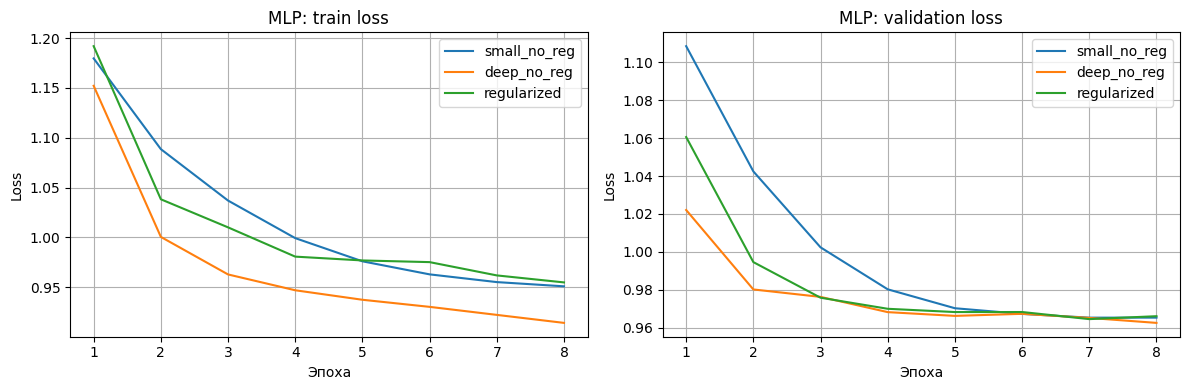

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in mlp_histories.items():
    # Постройте train loss и validation loss для каждой конфигурации
    axes[0].plot(history['epoch'], history['train_loss'], label=name)
    axes[1].plot(history['epoch'], history['loss'], label=name)

axes[0].set_title("MLP: train loss")
axes[1].set_title("MLP: validation loss")

for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

**Вывод по эксперименту 1**

Соберите результаты в одну сравнительную таблицу. Постройте кривые обучения и сравните поведение моделей. Ответьте на вопросы:

* Какая MLP-конфигурация сработала лучше с точки зрения метрики PR-AUC? Что показывают остальные метрики этого запуска?
* Продолжает ли уменьшаться loss на обучающей выборке, когда loss на валидационной выборке уже растёт или перестаёт улучшаться?
* Помогли ли слои `Dropout` и `weight_decay` уменьшить переобучение?
* Почему числовых признаков может быть недостаточно для анализа тональности?

Если вы выполняли дополнительное задание, также расскажите, совпали ли ожидания от конфигурации с результатом.

По максимальному PR-AUC на валидационной выборке выбрана regularized

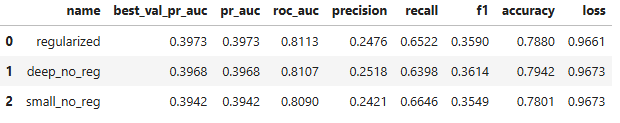

На тестовой выборке у той же модели получены следующие результаты

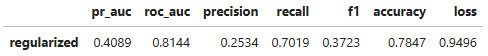


По кривым обучения train loss у всех моделей продолжает снижаться, тогда как улучшение validation loss к последним эпохам замедляется.

Регуляризация ограничивает подгонку обучающей выборки, однако устойчивого роста validation loss у нерегуляризованной MLP не наблюдается. Регуляризованная модель показала немного более высокий PR-AUC на валидационной выборке. Однако разница около 0,0005 слишком мала чтобы утверждать о преимуществе регуляризации

Числовые признаки описывают длину и оформление отзыва, число знаков препинания, долю заглавных букв и другие поверхностные характеристики. Они позволяют обнаруживать косвенные закономерности, но не передают смысл слов и поэтому ограничивают качество классификации тональности

## Шаг 5. Эксперимент 2 — Embedding + mean pooling + MLP

В ходе второго эксперимента вы передадите в нейросеть тексты отзывов, а не только их числовые признаки. Используйте те же обучающую, валидационную и тестовую выборки, что и в первом эксперименте.

Далее вам нужно:

1. Подготовить текст — использовать готовую токенизацию, построить словарь только по обучающей выборке и перевести слова в индексы.
2. Собрать `Dataset` для текстов — реализовать длину датасета, получение одного объекта, обрезание длинных отзывов и пэддинг коротких отзывов до `MAX_LENGTH`.
3. Описать модель — получить эмбеддинги, исключить PAD-токены маской, усреднить эмбеддинги настоящих токенов и передать итоговый вектор в MLP.
4. Обучить модель через уже готовый `run_experiment`, оценить качество на тестовой выборке и сохранить веса через `state_dict`. Новый цикл обучения писать не нужно.
5. Провести анализ ошибок: найти конкретные примеры ответов типа FP и FN, чтобы объяснить, почему модель могла ошибиться.

### 5.1. Готовая подготовка текста

Код для токенизации и построения словаря уже почти полностью готов. Ваша задача — запустить ячейку и проверить, что словарь действительно строится **только по обучающей выборке**.

Обратите внимание на три специальных элемента логики:

- `PAD_IDX` — индекс для добивки коротких текстов до одной длины.
- `UNK_IDX` — индекс для редких или неизвестных слов. Подробнее этот элемент вы рассмотрите в следующем спринте.
- `text_to_indices` — функция, которая превращает текст в список индексов словаря.

После запуска проверьте размер словаря и первые элементы: это быстрый способ убедиться, что подготовка текста прошла корректно.

In [34]:
TOKEN_RE = re.compile(r"[а-яёa-z0-9]+", flags=re.IGNORECASE)
PAD_IDX = 0
UNK_IDX = 1


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(str(text).lower())


def build_vocab(texts, min_freq: int = 2, max_size: int = 20_000) -> dict:
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))

    vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}
    for token, count in counter.most_common(max_size - len(vocab)):
        if count >= min_freq:
            vocab[token] = len(vocab)

    return vocab


def text_to_indices(text: str, vocab: dict) -> list[int]:
    return [vocab.get(token, UNK_IDX) for token in tokenize(text)]


vocab = build_vocab(train_df["text"], min_freq=2, max_size=20_000)
print(f"Размер словаря: {len(vocab)}")
print("Первые элементы словаря:", list(vocab.items())[:10])

Размер словаря: 18582
Первые элементы словаря: [('<PAD>', 0), ('<UNK>', 1), ('и', 2), ('в', 3), ('на', 4), ('не', 5), ('очень', 6), ('с', 7), ('что', 8), ('все', 9)]


### 5.2. Dataset и пэддинг

В этой части нужно дописать класс `ReviewsTextDataset`:

1. Верните количество текстов в датасете в `__len__`.
2. Возьмите текст по индексу и переведите его в индексы токенов в `__getitem__`.
3. Обрежьте слишком длинные отзывы до `MAX_LENGTH`.
4. Дополните короткие отзывы значением `PAD_IDX`, чтобы все последовательности в батче были одинаковой длины.
5. Создайте `DataLoader` для обучающей, валидационной и тестовой выборок.
6. Проверьте форму первого батча: ожидается матрица размера `batch_size` × `MAX_LENGTH` и тип `torch.long` для индексов токенов.

In [36]:
class ReviewsTextDataset(Dataset):
    def __init__(self, texts, target, vocab: dict, max_length: int = 120):
        self.texts = list(texts)
        self.target = np.array(target, dtype=np.float32)
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        # Верните количество текстов
        return len(self.texts)

    def __getitem__(self, idx):
        ids = text_to_indices(self.texts[idx], self.vocab)

        # Обрежьте последовательность до max_length
        ids = ids[:self.max_length]

        # Если последовательность короче max_length, добавьте PAD_IDX
        if len(ids) < self.max_length:
            ids = ids + [PAD_IDX] * (self.max_length - len(ids))

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor([self.target[idx]], dtype=torch.float32),
        )


MAX_LENGTH = 120

text_loaders = {
    "train": DataLoader(
        ReviewsTextDataset(
            train_df["text"],
            y_train,
            vocab,
            max_length=MAX_LENGTH
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsTextDataset(
            val_df["text"],
            y_val,
            vocab,
            max_length=MAX_LENGTH
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsTextDataset(
            test_df["text"],
            y_test,
            vocab,
            max_length=MAX_LENGTH
        ),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

ids_batch, text_target_batch = next(iter(text_loaders["train"]))
print("ids_batch:", ids_batch.shape, ids_batch.dtype)
print("target_batch:", text_target_batch.shape, text_target_batch.dtype)

ids_batch: torch.Size([128, 120]) torch.int64
target_batch: torch.Size([128, 1]) torch.float32


### 5.3. Модель с Embedding и mean pooling

В этой части нужно дописать `forward` модели `EmbeddingMLP`.

Что вам нужно сделать внутри `forward`:

1. Передать `input_ids` в `nn.Embedding`, чтобы каждому индексу токена соответствовал обучаемый вектор.
2. Умножить эмбеддинги на маску и посчитать длину каждого текста без PAD-токенов.
3. Выполнить mean pooling: усреднить эмбеддинги настоящих токенов и получить один вектор на отзыв.
4. Передать этот вектор в MLP-классификатор и вернуть логит.

In [38]:
class EmbeddingMLP(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 64,
        hidden_dim: int = 64,
        dropout: float = 0.3,
        pad_idx: int = PAD_IDX,
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx,
        )
        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )
        self.pad_idx = pad_idx

    def forward(self, input_ids):
        # 1. Получите эмбеддинги
        embeddings = self.embedding(input_ids)

        # 2. PAD-токены нужны только для выравнивания длин
        # Маска помогает не учитывать их при усреднении
        mask = (input_ids != self.pad_idx).unsqueeze(-1)
        masked_embeddings = embeddings * mask
        lengths = mask.sum(dim=1).clamp(min=1)

        # 3. Выполните mean pooling и передайте результат в MLP
        pooled = masked_embeddings.sum(dim=1) / lengths
        logits = self.classifier(pooled)
        return logits

### 5.4. Обучение, оценка и сохранение

Используйте тот же `run_experiment`, что и для MLP на числовых признаках. Это важно: цикл обучения и цикл валидации не нужно писать второй раз.

Что нужно сделать в коде:

1. Проверьте конфигурацию текстовой модели: размер эмбеддинга, размер скрытого слоя, `dropout`, `lr` (learning rate), `weight_decay` и число эпох.
2. Создайте объект `EmbeddingMLP` с нужным размером словаря.
3. Запустите обучение через `run_experiment`.
4. Посчитайте метрики на тестовой выборке с помощью `evaluate`.
5. Постройте график loss на обучающей и валидационной выборках.
6. Сохраните веса обученной текстовой модели через `state_dict`.

In [40]:
text_config = {
    "embedding_dim": 64,
    "hidden_dim": 64,
    "dropout": 0.3,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "epochs": 8,
}

set_seed(RANDOM_STATE)

text_model = EmbeddingMLP(
    vocab_size=len(vocab),
    embedding_dim=text_config["embedding_dim"],
    hidden_dim=text_config["hidden_dim"],
    dropout=text_config["dropout"],
)

text_model, text_history = run_experiment(text_model, text_loaders, text_config)
text_test_metrics, y_true_text_test, y_prob_text_test = evaluate(
    text_model,
    text_loaders["test"],
    criterion,
    device,
)

display(pd.DataFrame([text_test_metrics]).round(4))

,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,0.628,0.9431,0.5095,0.8323,0.6321,0.9119,0.667


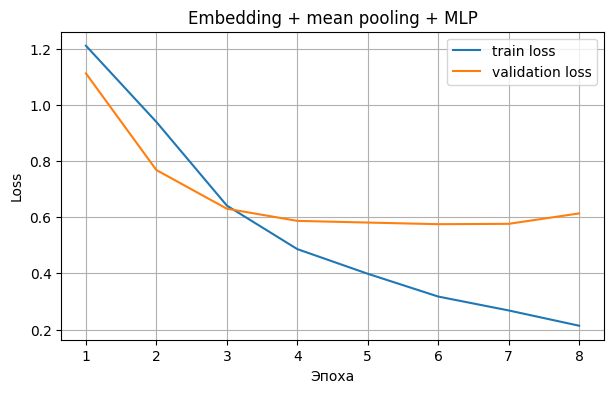

In [41]:
plt.figure(figsize=(7, 4))

# Постройте train loss и validation loss для текстовой модели
plt.plot(text_history['epoch'], text_history['train_loss'], label="train loss")
plt.plot(text_history['epoch'], text_history['loss'], label="validation loss")

plt.title("Embedding + mean pooling + MLP")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

In [42]:
best_text_path = MODELS_DIR / "best_embedding_mlp.pt"

# Сохраните веса текстовой модели через state_dict
torch.save(text_model.state_dict(), best_text_path)

print(f"state_dict текстовой модели сохранён в: {best_text_path}")

state_dict текстовой модели сохранён в: models\best_embedding_mlp.pt


### 5.5. Анализ ошибок текстовой модели

После обучения нужно посмотреть на конкретные ошибки, чтобы разобраться, что именно не ухватывает модель.

Что нужно найти:

- Ложноположительные примеры (FP) — модель посчитала отзыв негативным (класс 1), хотя его истинный класс равен 0.
- Ложноотрицательные примеры (FN) — модель не распознала негативный отзыв (класс 1).

Для каждого типа ошибки проанализируйте текст, вероятность негативного отзыва и возможную причину. Обратите внимание на смешанную тональность, короткие отзывы, отрицания, сарказм, длинный контекст и потерю порядка слов при mean pooling.

Также учитывайте возможный шум разметки: `target` получен из пользовательской оценки, а не из ручного анализа текста.

In [44]:
error_analysis = test_df[["text", "target", "review_len_words"]].copy()
error_analysis["prob_negative"] = y_prob_text_test
error_analysis["prediction"] = (error_analysis["prob_negative"] >= 0.5).astype(int)

# Найдите false positive: модель считает отзыв негативным, но target = 0
# Полезно отсортировать такие примеры по prob_negative по убыванию
false_positive = error_analysis[
    (error_analysis["target"] == 0)
    & (error_analysis["prediction"] == 1)
].sort_values("prob_negative", ascending=False)

# Найдите false negative: модель пропускает негативный отзыв
# Полезно отсортировать такие примеры по prob_negative по возрастанию
false_negative = error_analysis[
    (error_analysis["target"] == 1)
    & (error_analysis["prediction"] == 0)
].sort_values("prob_negative", ascending=True)

print(f"Всего FP: {len(false_positive)}, FN: {len(false_negative)}")

print("False positive: модель считает отзыв негативным, но target = 0")
display(false_positive)

print("False negative: модель пропускает негативный отзыв")
display(false_negative)

Всего FP: 129, FN: 27
False positive: модель считает отзыв негативным, но target = 0


,text,target,review_len_words,prob_negative,prediction
3746,Не всё купили что надо,0,5,0.999388,1
10024,"Контора с понятиями! Встречают как надо,обещания выполняют. Справки не нужны,можно даже ВИЧ инфицированным работать. Главное при отлове птиц не повредить кожный покров. Чтоб не попасть в просак",0,29,0.998739,1
4011,"Медленно, печально,на кассе такое ощущение что просто тянут время.\nОдин сотрудник в отделе декора,которому просто не разорваться",0,19,0.998493,1
7353,"Оплата только картой. Шаг 50 рублей, меньше ввести не получилось.\nОтличная идея закрыть с третьей стороны стенкой, от порыва ветра брызги не разлетаются",0,23,0.997588,1
5206,"Водитель на отгрузке простоял в очереди за фурами 2 часа, что бы загрузить 800 кг. Сотрудники аргументировали тем, что у меня металл с порезкой, а так бы без очереди отгрузили... В итоге уехали без груза, т к. уже на...",0,87,0.996334,1
...,...,...,...,...,...
2766,"Мнение неоднозначное! \nФуд-Парк!\nБыло, обрадовался тому, что фуд-корт в Тополе лучше, чем в Ясене и, наконец-то, можно найти ""на одном пятачке"" все, что угодно, на любой вкус и по достаточно приятным ценам. В этом ...",0,297,0.516807,1
9169,"Нормальная пекарня, не хуже и не лучше других. Интерьер приятный.",0,10,0.514754,1
3728,"По телефону не получил ни одного вразумительного ответа на свои вопросы! Ни по стоимости и времени замены (надо узнавать), ни по другим вопросам. Единственное, что со знанием дела предложили - это доплатить значитель...",0,55,0.514619,1
4706,"Очень хороший клуб, многофункциональный. Хожу на групповые занятия, дорабатываю в тренажеке и затем релакс в водной зоне.\nЗвёздочку сняла за прохладную воду в душевых! Промыть голову в такой воде не реально!\nХотела...",0,61,0.503983,1


False negative: модель пропускает негативный отзыв


,text,target,review_len_words,prob_negative,prediction
9989,"Цены зашкаливают, не для нашего города.",1,6,0.000448,0
1903,Очень долго ходить автобус,1,4,0.001088,0
8255,"И место хорошее и обслуживание замечательно и вежливы и приветливы и аккуратны , Одно очень расстроило Мороженное Отвратительное ледышки вместо замечательного лакомства",1,21,0.001871,0
11718,Очень бедная больница. Все лекарства для лечения покупали сами .. Также была аллергия у ребёнка ни кто не дал даже таблетки от аллергии. Сказали нету... Дети и взрослые лежат все вместе. Одно радовала то что женщин...,1,45,0.009927,0
7010,"Отравились всей семьёй. 🤦‍♀️ персонал конечно тоже грубоват. Вроде в самом классном месте находятся, а умудряются так испортить отдых...",1,18,0.020401,0
1078,"Узкий профиль продаж. Пару мелочей из списка необходимого для дома, не нашлось.",1,12,0.022890,0
6808,"Само помещение в ужасном состоянии, врачи-педиаторы в основном хорошие. К узким специалистам очень сложно попасть, талоны ни в интернете, ни в терминале взять нереально",1,25,0.041753,0
3343,"Место хорошее, парк сохранил кусочками советскую задумку планировку, дендрологический, но заброшен, кто-то начинал переделывать,, но,,,,,,, впечатление одичавшего лес очка, своя предисловии, в это есть отдых от цивил...",1,55,0.046526,0
5168,Стал дорогим с сильно поредевшим ассортиментом. Когда-то стоимость некоторых товаров можно было компенсировать хорошей скидкой по другим либо наличием интересных (эксклюзивных) вариантов для покупки. Сейчас всё тоже ...,1,76,0.051022,0
5658,"Не нравиться, особенно если ехать с города! Если есть варианты и альтернативы , туда не поеду 😩",1,15,0.059925,0


**Анализ найденных ошибок**

Заполните два коротких списка:

- FP — какие слова или фрагменты могли подтолкнуть модель посчитать отзыв отрицательным, хотя `target = 0`.
- FN — почему модель могла пропустить отзыв класса 1. Возможные причины: редкие слова, длинный контекст, отрицания или слабые негативные маркеры.

Отдельно отметьте, могли ли дисбаланс классов и разметка по пользовательским оценкам повлиять на ошибки: отзывы с оценкой 3–5 попадают в `target = 0`, хотя текст иногда бывает нейтральным или смешанным.

При пороге 0,5 на тестовой выборке найдено 129 FP и 27 FN

**FP**:
  * Индекс 3746, target = 0, prob_negative = 0,9993: `«Не всё купили что надо»`. Отрицание и сообщение о неудовлетворённой потребности выглядят как критика
  * Индекс 4011, target = 0, prob_negative = 0,9984: «`Медленно, печально,на кассе такое ощущение что просто тянут время.\nОдин сотрудник в отделе декора,которому просто не разорваться`» Текст явно содержит недовольство обслуживанием. Здесь правдоподобно расхождение между тональностью текста и меткой, полученной из оценки; утверждать, что сама оценка ошибочна, нельзя

**FN**:
  * Индекс 9989, target = 1, prob_negative = 0,0005: `«Цены зашкаливают, не для нашего города»`. Короткая жалоба на дороговизну не содержит типичных слов вроде "ужасно". Возможно модель недостаточно выучила сочетание слов "цены зашкаливают"
  * Индекс 1903, target = 1, prob_negative = 0,0011: `«Очень долго ходить автобус»`. Текст короткий; недовольство выражено через длительность ожидания. Без контекста отрицательный смысл может быть потерян

Негативных отзывов значительно меньше, поэтому модель получает меньше примеров этого класса. Взвешивание функции потерь через pos_weight помогает учитывать негативный класс, но не устраняет недостаток примеров

Разметка по оценкам также может влиять на ошибки: отзывы с оценками 3–5 относятся к классу 0, даже если содержат критику. Поэтому некоторые FP могут отражать реальное недовольство в тексте, хотя формально предсказание не совпадает с target

**Вывод по эксперименту 2**

Ответьте на вопросы:

* Насколько текстовая модель лучше или хуже MLP на числовых признаках по PR-AUC? Что показывают остальные метрики?
* Какие ошибки вы нашли среди false positive и false negative?
* Какие причины ошибок кажутся наиболее вероятными?
* Какие ограничения остаются у mean pooling?
* Почему текстовое представление обычно даёт модели больше информации, чем поверхностные числовые признаки?

Текстовая модель превосходит выбранную числовую MLP по всем рассматриваемым тестовым метрикам: PR-AUC увеличился с 0,4089 до 0,6280. ROC-AUC вырос с 0,8144 до 0,9431, precision — с 0,2534 до 0,5095, recall — с 0,7019 до 0,8323, F1 — с 0,3723 до 0,6321. При пороге 0,5 текстовая модель одновременно находит больше негативных отзывов и делает меньше ложных срабатываний

Среди FP встречаются отзывы, отнесённые по оценке к классу 0, и смешанные отзывы. Среди FN — короткие жалобы на цены и ожидание, а также отзывы с положительным вступлением и важной отрицательной концовкой. вероятные причины: расхождение оценки и текста, недостаточно выученные выражения и усреднение положительных и отрицательных слов

На кривых видны признаки переобучения: после 6 эпохи validation loss растёт с 0.5749 до 0.5761, а train loss снижается с 0.3173	 до 0.2679. При этом validation PR-AUC продолжает расти и достигает максимума 0.7204 на 8 эпохе, поэтому по принятому критерию сохраняется именно восьмая эпоха

Обучаемые эмбеддинги дают модели доступ к лексике отзыва, которой нет у поверхностных числовых признаков. Однако mean pooling не учитывает порядок слов, область действия отрицания, противопоставления и сарказм; важная информация может раствориться среди остальных слов. Дополнительно отзывы обрезаются до 120 токенов. Таким образом, текстовое представление информативнее, но не обеспечивает полноценного понимания контекста

## Шаг 6. Итоговое сравнение

Для честного выбора лучшей числовой MLP используйте PR-AUC на валидационной выборке, потому что положительный класс редкий. ROC-AUC, precision, recall, F1 и accuracy нужны для дополнительной диагностики. Метрики на тестовой выборке анализируем уже после выбора модели.

Ниже соберите сравнительную таблицу минимум с двумя строками: лучшая MLP на числовых признаках и `Embedding + pooling + MLP`.

In [50]:
final_comparison = pd.DataFrame(
    [
        {
            "Подход": "MLP на числовых признаках",
            "PR-AUC test": best_mlp_test_metrics["pr_auc"],
            "ROC-AUC test": best_mlp_test_metrics["roc_auc"],
            "Precision": best_mlp_test_metrics["precision"],
            "Recall": best_mlp_test_metrics["recall"],
            "F1": best_mlp_test_metrics["f1"],
            "Ограничения": "Не учитывает слова и смысл отзыва; использует поверхностные характеристики текста",
        },
        {
            "Подход": "Embedding + pooling + MLP",
            "PR-AUC test": text_test_metrics["pr_auc"],
            "ROC-AUC test": text_test_metrics["roc_auc"],
            "Precision": text_test_metrics["precision"],
            "Recall": text_test_metrics["recall"],
            "F1": text_test_metrics["f1"],
            "Ограничения": "Не учитывает порядок слов; обрезает текст до 120 токенов",
        },
    ]
)

display(final_comparison)

,Подход,PR-AUC test,ROC-AUC test,Precision,Recall,F1,Ограничения
0,MLP на числовых признаках,0.408861,0.814421,0.253363,0.701863,0.372323,Не учитывает слова и смысл отзыва; использует поверхностные характеристики текста
1,Embedding + pooling + MLP,0.628047,0.943138,0.509506,0.832298,0.632075,Не учитывает порядок слов; обрезает текст до 120 токенов


## Итоговые выводы

Сформулируйте итоговые выводы. Ответьте на вопросы:

* Какой подход показал лучшее качество?
* По каким метрикам преимущество особенно заметно?
* Что текстовая модель узнала из того, что упускала модель на числовых признаках?
* В каких ситуациях числовые признаки всё же могут быть полезны?
* Какие ограничения есть у mean pooling?
* Как на результат могли повлиять дисбаланс классов и разметка, полученная из пользовательских оценок?
* Какой следующий эксперимент вы бы предложили?

В проведённом эксперименте лучшим по качеству оказался подход Embedding + mean pooling + MLP. Ключевое метрикой для выбора является PR-AUC

Особенно заметны улучшения:
  * PR-AUC: 0.4088 → 0.628
  * precision: 0.2534 → 0.5095
  * F1: 0.3723 → 0.6321
  * recall → 0.7019 до 0.8323

Текстовое представление позволяет использовать слова и выражения, связанные с недовольством или похвалой. Числовая модель видит лишь форму текста и сопутствующие признаки. По результатам нельзя точно установить, какие отдельные слова выучила сеть, но доступ к лексике даёт существенно более высокое качество

Числовые признаки полезны для построения простой базовой модели и как дополнение к текстовому представлению. Они сохраняют информацию о длине отзыва, пунктуации и эмодзи, которая может теряется при токенизации

Основные ограничения mean pooling — потеря порядка слов, невозможность явно учитывать противопоставления и область действия отрицания, одинаковое усреднение важных и второстепенных токенов. Обрезание длинных отзывов дополнительно сокращает информативность

Негативные отзывы составляют только 9,10% данных. Взвешивание loss помогает учитывать редкий класс, но не создаёт новых примеров и не устраняет дисбаланс. По условию используется порог 0,5, поэтому его подбор в этом проекте не проводится. Дисбаланс учитывается через pos_weight. Метки по пользовательским оценкам также ограничивают результат

Следующий эксперимент — добавить к усреднённому текстовому вектору стандартизированные числовые признаки и one-hot-код округа, сохранив текущее разбиение и сравнивая варианты по validation PR-AUC. Это позволит проверить, дополняют ли структурные признаки лексику. Текущий test уже использован для итоговой оценки: дальнейшие решения по нему принимать не следует; для окончательной независимой проверки доработанной модели потребуется новый отложенный набор. В дальнейшем отдельным экспериментом можно проверить модель, учитывающую порядок слов, чтобы адресовать ошибки с отрицаниями и противопоставлениями.